In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from google.colab import files
uploaded = files.upload()

dataset = pd.read_csv('50_Startups.csv')

dataset

Saving 50_Startups.csv to 50_Startups.csv


,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94
5,131876.90,99814.71,362861.36,New York,156991.12
6,134615.46,147198.87,127716.82,California,156122.51
7,130298.13,145530.06,323876.68,Florida,155752.60
8,120542.52,148718.95,311613.29,New York,152211.77
9,123334.88,108679.17,304981.62,California,149759.96


In [2]:
datasets = pd.get_dummies(dataset, drop_first=True, dtype=int)

display(datasets)

indep = datasets[
    ['R&D Spend', 'Administration', 'Marketing Spend',
     'State_Florida', 'State_New York']
]

dep = datasets[['Profit']]

print("Independent Variables:")
display(indep.head())

print("Dependent Variable:")
display(dep.head())

,R&D Spend,Administration,Marketing Spend,Profit,State_Florida,State_New York
0,165349.20,136897.80,471784.10,192261.83,0,1
1,162597.70,151377.59,443898.53,191792.06,0,0
2,153441.51,101145.55,407934.54,191050.39,1,0
3,144372.41,118671.85,383199.62,182901.99,0,1
4,142107.34,91391.77,366168.42,166187.94,1,0
5,131876.90,99814.71,362861.36,156991.12,0,1
6,134615.46,147198.87,127716.82,156122.51,0,0
7,130298.13,145530.06,323876.68,155752.60,1,0
8,120542.52,148718.95,311613.29,152211.77,0,1
9,123334.88,108679.17,304981.62,149759.96,0,0


Independent Variables:


,R&D Spend,Administration,Marketing Spend,State_Florida,State_New York
0,165349.20,136897.80,471784.10,0,1
1,162597.70,151377.59,443898.53,0,0
2,153441.51,101145.55,407934.54,1,0
3,144372.41,118671.85,383199.62,0,1
4,142107.34,91391.77,366168.42,1,0


Dependent Variable:


,Profit
0,192261.83
1,191792.06
2,191050.39
3,182901.99
4,166187.94


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    indep, dep,
    test_size=1/3,
    random_state=0
)

from sklearn.tree import DecisionTreeRegressor

regressor = DecisionTreeRegressor(random_state=0)

regressor = regressor.fit(X_train, y_train)

print("Decision Tree Regression Model Trained Successfully!")

Decision Tree Regression Model Trained Successfully!


In [4]:
y_pred = regressor.predict(X_test)

from sklearn.metrics import r2_score

r_score = r2_score(y_test, y_pred)

print("Actual Values:")
print(y_test.values.ravel())

print("Predicted Values:")
print(y_pred)

print("R2 Score:")
print(r_score)

Actual Values:
[103282.38 144259.4  146121.95  77798.83 191050.39 105008.31  81229.06
  97483.56 110352.25 166187.94  96778.92  96479.51 105733.54  96712.8
 124266.9  155752.6  132602.65]
Predicted Values:
[101004.64 129917.04 129917.04  78239.91 182901.99 118474.03  71498.49
 101004.64 118474.03 182901.99  89949.14  89949.14 126992.93  89949.14
 141585.52 156122.51 149759.96]
R2 Score:
0.8539797745006693


Feature Importance:
[9.80936057e-01 5.57016714e-03 1.29172578e-02 4.27181519e-04
 1.49336445e-04]
Maximum Features:
5
Tree Structure:


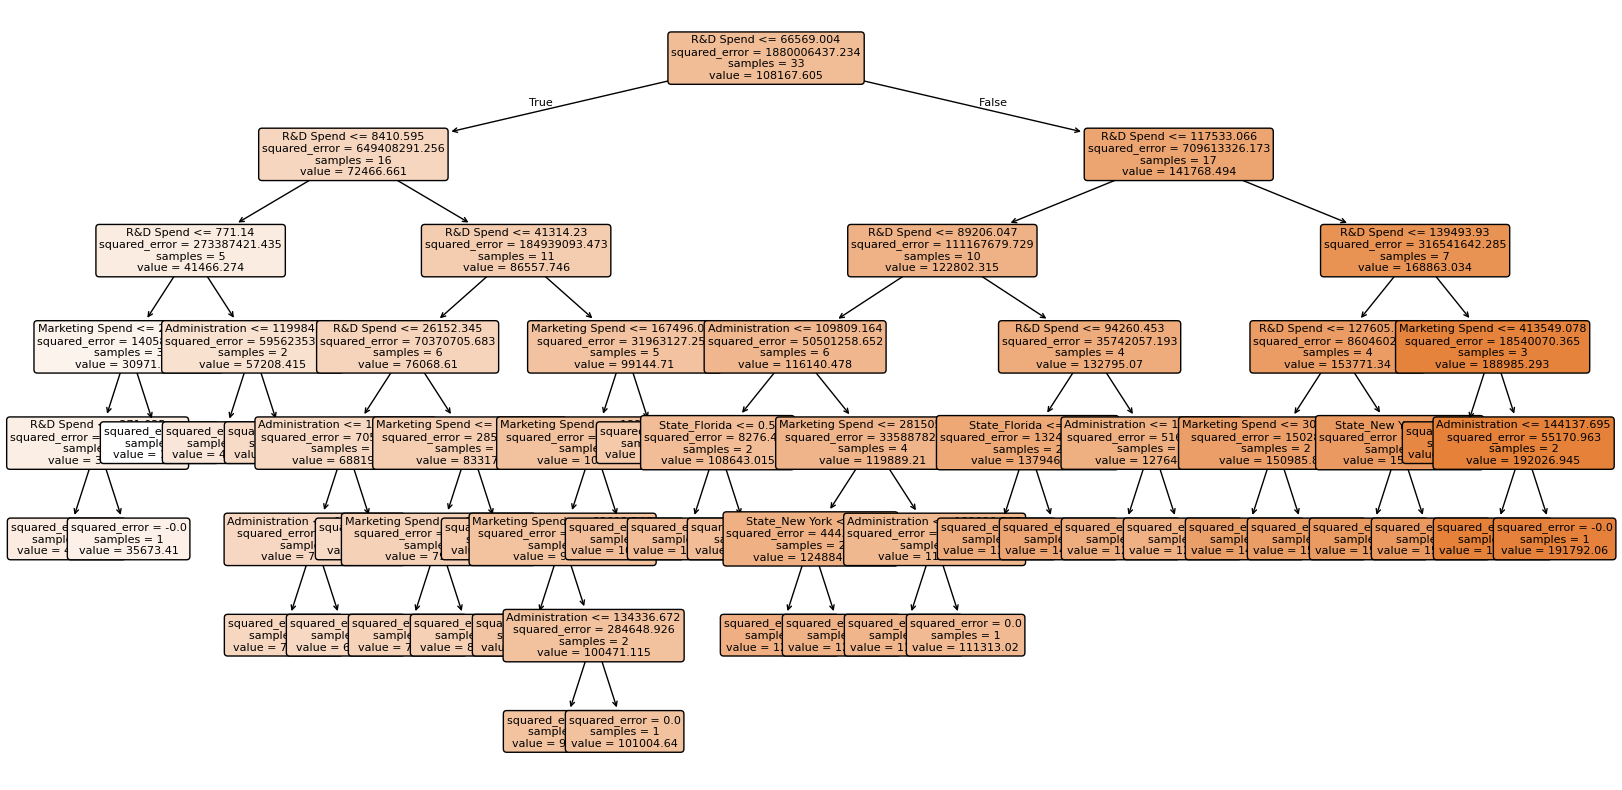

In [5]:
print("Feature Importance:")
print(regressor.feature_importances_)

print("Maximum Features:")
print(regressor.max_features_)

print("Tree Structure:")
print(regressor.tree_)

from sklearn import tree

plt.figure(figsize=(20, 10))

tree.plot_tree(
    regressor,
    feature_names=indep.columns,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()

In [7]:
rd_input = float(input("R&D Spend: "))

admin_input = float(input("Administration: "))

mark_input = float(input("Marketing Spend: "))

fol_input = int(input("State Florida (0 or 1): "))

new_input = int(input("State New York (0 or 1): "))


new_data = pd.DataFrame(
    [[rd_input, admin_input, mark_input, fol_input, new_input]],
    columns=indep.columns
)


result = regressor.predict(new_data)

print("Predicted Profit:", result[0])

R&D Spend: 22.1
Administration: 65.2
Marketing Spend: 2.1
State Florida (0 or 1): 0
State New York (0 or 1): 1
Predicted Profit: 42559.73
